In [1]:
import sys
import os

# Define the absolute path to the directory containing your module
module_folder_path = r'C:\Users\manue\OneDrive - University of Illinois - Urbana\Research\River corridor\inverse-river-transport\code' 


# Append the path to sys.path
sys.path.append(os.path.abspath(module_folder_path)) 
import utils
import forward
import estimators


import inspect

import numpy as np
import matplotlib.pyplot as plt

import scipy as sp
from scipy.stats import chi2

import csv

from matplotlib.colors import LogNorm

In [2]:
for module in [forward,estimators,utils]:
    print(module.__name__)
    for i, name_obj in enumerate(inspect.getmembers(module)):
        if '__' not in name_obj[0]:
            print('   ├--->',name_obj[0])
            for n,o in inspect.getmembers(name_obj[1],inspect.isfunction):
                if i != len(inspect.getmembers(module))-1:
                    print('   |       ├--->',n)
                else:
                    print('           ├--->',n)

forward
   ├---> laplace
           ├---> ADEMF_1D
           ├---> invlap
estimators
   ├---> PBI
   |       ├---> KL_coeffs
   |       ├---> drop_points_in_simplex
   |       ├---> estimate_params_NNI
   |       ├---> estimate_params_PBI
   |       ├---> get_projected_points
   |       ├---> get_projected_points_basis
   |       ├---> get_projecting_basis
   |       ├---> get_vertices_basis
   |       ├---> gs
   |       ├---> proj
   |       ├---> test_err_rand_KL_coeffs
   ├---> laplace
   |       ├---> ADEMF_1D
   ├---> moments
           ├---> ADEFO_1D
           ├---> TSM_moms_analyt
           ├---> TSM_moms_meas
utils
   ├---> dimensional_reduction
   |       ├---> KL_decomposition
   ├---> errors
   |       ├---> KL_div_func
   |       ├---> RMSD_func
   |       ├---> RMSE_func
   |       ├---> compute_errors
   ├---> invlap
   |       ├---> invlap
   ├---> load_btcs
   |       ├---> data
   ├---> synthetic
           ├---> ADEMF_1D
           ├---> generate
           ├---> 

In [3]:
help(estimators.laplace.ADEMF_1D)

Help on function ADEMF_1D in module estimators.laplace:

ADEMF_1D(t, btc, x, memory_func, bound_cond, params0, ns=10000)
    Estimates parameters of measured breakthrough curves by fitting in Laplace domain.
    - t (array): Times of measurement of concentrations
    - btc (array): Measured concentrations (same length as t)
    - memory_func (str): Either 'first order' or 'power law', others can be added editing beta_g_est_lap
    - bound_cond (str): Either 'semi-infinite-conc', 'semi-infinite-mixed', or 'infinite'
                'semi-infinite-conc' is a domain x>0 with vc(x=0,t)=M_0 delta(t)
                'semi-infinite-mixed' is a domain x>0 with vc(x=0,t)- 2 D dc/dx (x=0,t) =M_0 delta(t)
                'infinite' is a domain x>0 with vc(x=0,t)-2 D dc/dx (x=0,t) =M_0 delta(t). The solution to this problem is equivalent to the solution in the infinite domain
    - params0 (array of length 4): Initial guess of parameters. Default is v_ref and geometric mean of bounds. If bounds ar

In [4]:
with open(r"C:\Users\manue\OneDrive - University of Illinois - Urbana\Research\River corridor\inverse-river-transport\data\river_solute_tracer_data.csv", 'r') as file:
    data_reader = csv.reader(file)
    data_mat = [[cell for cell in row] for row in data_reader]
    breakthrough_curves_data = [[[data_mat[i][i_btc*5+j] for i in range(len(data_mat))] for j in range(4)] for i_btc in range(len(data_mat[0])//5)]

In [5]:
indices_valid = [i for i,btc in enumerate(breakthrough_curves_data) if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
ts_m = [np.array([float(c) for c in breakthrough_curves_data[i][0][33:] if c!='']) for i in indices_valid]
btcs_m = [np.array([float(c) for c in breakthrough_curves_data[i][3][33:] if c!='']) for i in indices_valid]
n_btcs = len(btcs_m)
for i_btc in range(n_btcs):
    if len(ts_m[i_btc])<len(btcs_m[i_btc]):
        btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
indices_unphysical = []
for i_btc in range(n_btcs):
    t,btc = ts_m[i_btc],btcs_m[i_btc]
    frac_ext = 1/3
    t_frac,btc_frac = t[btc>0][-int(len(btc[btc>0])*frac_ext):],np.log(btc[btc>0][-int(len(btc[btc>0])*frac_ext):])
    a,b = np.polyfit(t_frac,btc_frac,1)
    moms = estimators.moments.TSM_moms_meas(t,btc)
    if moms[2]<0 or a>0:
        indices_unphysical.append(indices_valid[i_btc])
for i in indices_unphysical:
    indices_valid.remove(i)
np.random.seed(42)
# indices_valid = list(np.random.choice(indices_valid,40,replace = False))

In [6]:
ts_m = [np.array([float(c) for c in breakthrough_curves_data[i][0][33:] if c!='']) for i in indices_valid]
btcs_m = [np.array([float(c) for c in breakthrough_curves_data[i][3][33:] if c!='']) for i in indices_valid]
xs_m = [breakthrough_curves_data[i][2][18] for i in indices_valid]
xs_m = [float(i) if i!='' else 0.0 for i in xs_m]
background_cs_m = [breakthrough_curves_data[i][2][25]  for i in indices_valid]
background_cs_m = [float(i) if i!='' else 0.0 for i in background_cs_m]
names_list = [breakthrough_curves_data[i][0][31]  for i in indices_valid]
n_btcs = len(ts_m)
rivers_list = [n.split(' ')[0] for n in names_list]
rivers_full_name_list = [breakthrough_curves_data[i][2][1] for i in indices_valid]
tracers_list = [' '.join(n.split(' ')[:2])+' '+''.join([j  if ('S'+j in n.split(' ')[-1]) else '' for j in list('ABCDEFGHIJKLMNOPQRSTUVWXYZ')]) for n in names_list]
unique_tracers_list = list(set(tracers_list))
_,count_tracers = np.unique([unique_tracers_list.index(i) for i in tracers_list], return_counts = True)
np.random.seed(1)
random_shuffle = np.arange(len(count_tracers))
np.random.shuffle(random_shuffle)

In [7]:
for i_btc in range(n_btcs):
    if len(ts_m[i_btc])<len(btcs_m[i_btc]):
        btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
T_= int(max([t[-1]/t[np.argmax(btc)] for t,btc in zip(ts_m,btcs_m)]))+1
print(T_)

24


In [8]:
ts_m_0 = []
btcs_m_0 = []
for i_btc in range(n_btcs):
    t,btc = ts_m[i_btc],btcs_m[i_btc]
    sorted_indices = np.argsort(t)
    t = t[sorted_indices]
    btc = btc[sorted_indices]
    t_unique,indices_unique = np.unique(t, return_index=True)
    if len(t_unique)!=len(t):
        btc_unique = np.zeros(len(indices_unique))
        for i in range(len(indices_unique)):
            if i<len(indices_unique)-1:
                btc_unique[i] = np.mean(btc[indices_unique[i]:indices_unique[i+1]])
            else:
                btc_unique[i] = np.mean(btc[indices_unique[i]:])
        t = t_unique
        btc = btc_unique
        ts_m[i_btc],btcs_m[i_btc] = t,btc
    deltat = np.median(t[1:]-t[:-1])
    t_ext = np.concatenate((np.arange(t[0],0,-deltat)[1:][::-1],t,np.arange(t[-1],max(t[-1],T_*t[np.argmax(btc)]),deltat)[1:]))
    btc_ext = np.interp(t_ext,t,btc-background_cs_m[i_btc],left = 0.0,right = 0.0)
    btc_ext = btc_ext
    ts_m_0.append(t_ext)
    btcs_m_0.append(btc_ext)

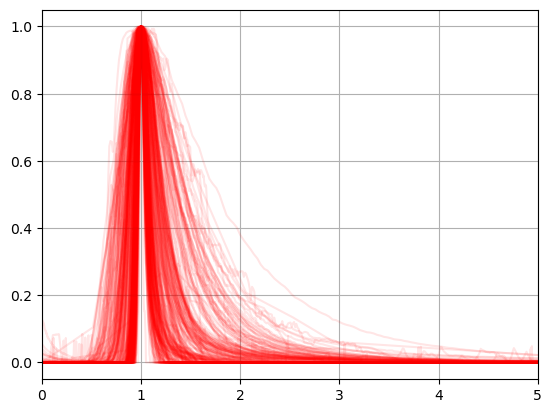

In [9]:
for i_btc in range(n_btcs):
    ts,btc = ts_m_0[i_btc],btcs_m_0[i_btc]
    plt.grid()
    plt.plot(ts/ts[np.argmax(btc)],btc/np.max(btc), c = 'r', alpha = 0.1)
    plt.xlim(0,5)

## Parameter estimation

In [10]:
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

In [79]:
memory_func = 'power law'
bound_cond = 'infinite'

In [80]:
vs_peak = np.array([x/ts_meas[np.argmax(measured_bt)] for ts_meas,measured_bt,x in zip(ts_m_0,btcs_m_0,xs_m)])
ts_peak = np.array([ts_meas[np.argmax(measured_bt)] for ts_meas,measured_bt,x in zip(ts_m_0,btcs_m_0,xs_m)])

In [156]:
%%time
def estimate_laplace(i_btc):
    t,btc,x, v_ref = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc], vs_peak[i_btc]
    t_pos = t[btc>0]
    btc_pos = btc[btc>0]
    if memory_func == 'first order':
        params0 = np.array([vs_peak[i_btc],100.0,3.0,30.0])
    if memory_func == 'power law':
        params0 = np.array([vs_peak[i_btc],100.0,0.3,0.5])
    params = estimators.laplace.ADEMF_1D(t_pos,btc_pos,x,memory_func,bound_cond,params0)
    if memory_func == 'first order':
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]
    if memory_func == 'power law':
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),1.0,[params[2],params[3]],memory_func,bound_cond)[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),1.0,[params[2],params[3]],memory_func,bound_cond)[:,-1]
    RMSD = utils.errors.RMSD_func(t,btc,btc_rec)
    KL_div = utils.errors.KL_div_func(t,btc,btc_rec)
    if memory_func == 'power law':
        params[-1] = np.exp(params[-1])
    return params,RMSD,KL_div,btc_rec
output_estimate_laplace = [estimate_laplace(i_btc) for i_btc in range(n_btcs)]
params_laplace = np.array([out[0] for out in output_estimate_laplace])
RMSDs_laplace = np.array([out[1] for out in output_estimate_laplace])
KL_divs_laplace = np.array([out[2] for out in output_estimate_laplace])
btcs_rec_laplace = [out[3] for out in output_estimate_laplace]

CPU times: total: 49.1 s
Wall time: 49.5 s


In [157]:
%%time
if memory_func == 'first order':
    def estimate_moments(i_btc):
        t,btc,x = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc]
        v_prior = x/t[np.argmax(btc)]
        params0 =  np.array([v_prior,300.0,3.0,30.0])
        params = estimators.moments.ADEFO_1D(t,btc,x,bound_cond,params0)
        if t[0]==0:
            btc_rec = np.concatenate(([0.0],forward.laplace.ADEMF_1D(t[1:],[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]))
        else:
            btc_rec = forward.laplace.ADEMF_1D(t,[x],params[0],min(params[1],20000),params[2]/params[3],[params[3],params[3]],memory_func,bound_cond)[:,-1]
        RMSD = utils.errors.RMSD_func(t,btc,btc_rec)
        KL_div = utils.errors.KL_div_func(t,btc,btc_rec)
        return params,RMSD,KL_div,btc_rec
    output_estimate_moments = [estimate_moments(i_btc) for i_btc in range(n_btcs)]
    params_moments = np.array([out[0] for out in output_estimate_moments])
    RMSDs_moments = np.array([out[1] for out in output_estimate_moments])
    KL_divs_moments = np.array([out[2] for out in output_estimate_moments])
    btcs_rec_moments = [out[3] for out in output_estimate_moments]

CPU times: total: 0 ns
Wall time: 0 ns


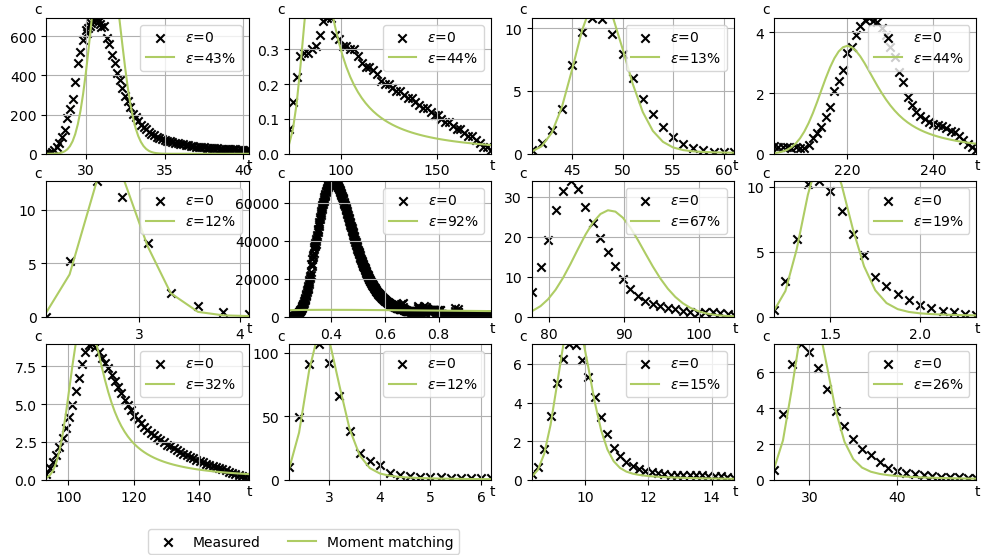

In [158]:
from matplotlib.transforms import offset_copy
# np.random.seed(1)
Nrows = 3
Ncols = 4
fig,axes = plt.subplots(nrows = Nrows, ncols = Ncols, figsize = (12,6))
np.random.seed(42)
rand_i_btcs = np.sort(np.random.choice(list(range(n_btcs)),size = Nrows*Ncols, replace = False))
j=0
for i_btc in rand_i_btcs:
    t,btc,x,est_btc_lap = ts_m_0[i_btc],btcs_m_0[i_btc],xs_m[i_btc],btcs_rec_laplace[i_btc]
    axes[j//Ncols][j%Ncols].scatter(t,btc, c='k', marker = 'x',label = '$\epsilon$=0')
    axes[j//Ncols][j%Ncols].set_ylabel('c', rotation=0)
    axes[j//Ncols][j%Ncols].set_xlabel('t', loc='right', labelpad=-10)
    if memory_func == 'first order':
        est_btc_mom = btcs_rec_moments[i_btc]
        axes[j//Ncols][j%Ncols].plot(t, est_btc_mom*np.trapezoid(btc,t)/np.trapezoid(est_btc_mom,t),label = r'$\epsilon$='+format(RMSDs_moments[i_btc],'.0%'), c = colors[0])
    
    axes[j//Ncols][j%Ncols].plot(t, est_btc_lap*np.trapezoid(btc,t)/np.trapezoid(est_btc_lap,t),label = r'$\epsilon$='+format(RMSDs_laplace[i_btc],'.0%'), c = colors[1])
    
    axes[j//Ncols][j%Ncols].set_xlim(t[btc>np.max(btc)*0.001][0],t[btc>np.max(btc)*0.01][-1])
    axes[j//Ncols][j%Ncols].set_ylim(0.0,np.max(btc))
    # axes[j//Ncols][j%Ncols].set_title(names[i_btc], loc='right',pad = -50)
    axes[j//Ncols][j%Ncols].legend()

    axes[j//Ncols][j%Ncols].grid()
    axes[j//Ncols][j%Ncols].yaxis.set_label_coords(-0.04,1.01)
    axes[j//Ncols][j%Ncols].xaxis.set_label_coords(1.02,-0.03)

    j+=1
handles, _ = axes[-1][-1].get_legend_handles_labels()
if memory_func == memory_func:
    labels = ['Measured','Moment matching', 'Laplace domain fitting']#, 'KL-DNN-MAP']
else:
    labels = ['Measured', 'Laplace domain fitting', 'KL-DNN-MAP']
fig.legend(handles, labels, loc=(0.15,0.0015), ncols = 3)

In [159]:
best_params_prior = params_laplace.copy()
if memory_func == 'first order':
    best_params_prior[RMSDs_moments<RMSDs_laplace] = params_moments[RMSDs_moments<RMSDs_laplace]

In [160]:
dim_scaling = np.concatenate((vs_peak[:,None],np.ones(n_btcs)[:,None],np.ones(n_btcs)[:,None],np.ones(n_btcs)[:,None]),axis = 1)
dimless_best_params_prior = best_params_prior/dim_scaling

In [161]:
if memory_func == 'first order':
    RMSDs_best_prior = np.minimum(RMSDs_laplace,RMSDs_moments)
    is_outlier = RMSDs_best_prior>0.25
else:
    RMSDs_best_prior = RMSDs_laplace
    is_outlier = RMSDs_best_prior>0.4

print(np.mean(is_outlier))
mean_log_params = np.mean(np.log(dimless_best_params_prior)[~is_outlier], axis=0)
cov_log_params = np.cov(np.log(dimless_best_params_prior)[~is_outlier], rowvar=0)
cov_log_params_sqrt = sp.linalg.sqrtm(cov_log_params)

0.39100346020761245


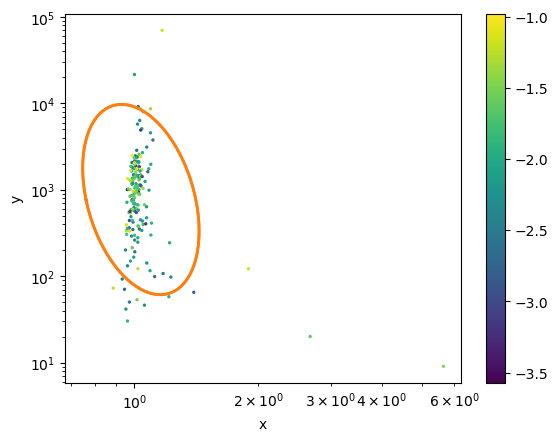

In [162]:
pars_index = [0,1]
# 1️⃣ Eigen-decomposition
eigvals, eigvecs = np.linalg.eigh(4*cov_log_params[pars_index][:,pars_index])

# 2️⃣ Parameterize unit circle
theta = np.linspace(0, 2*np.pi, 200)
circle = np.vstack((np.cos(theta), np.sin(theta)))

# 3️⃣ Scale to ellipse in log-space
ellipse_log = (
    eigvecs @ np.diag(np.sqrt(eigvals)) @ circle
    + mean_log_params[pars_index][:,None]
)

# 4️⃣ Transform back to original space
ellipse = np.exp(ellipse_log)

# 5️⃣ Plot
plt.figure()
plt.loglog(ellipse[0], ellipse[1], 'tab:orange', lw=2)
plt.loglog(ellipse[0], ellipse[1], 'tab:orange', lw=2)
plt.scatter(*dimless_best_params_prior[~is_outlier][:,pars_index].T, c = np.log(np.minimum(RMSDs_laplace,RMSDs_moments)[~is_outlier]), s = 2.0)
plt.colorbar()
plt.xscale('log')
plt.yscale('log')
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [163]:
from scipy.stats import chi2

rivers   = np.array(rivers_full_name_list)                      # check: len(np.unique(rivers)) should be 25
logp     = np.log(dimless_best_params_prior)[:, 1:]   # log(Pe, beta*kf, kr)
ok       = ~is_outlier   # same outlier rule, all BTCs
d        = logp.shape[1]
r99      = chi2.ppf(0.99, d)

def stats(X): return X.mean(0), np.cov(X, rowvar=False)

def kl_gauss(m0, S0, m1, S1):                         # KL(N0 || N1)
    S1i = np.linalg.inv(S1); dm = m1 - m0
    return 0.5*(np.trace(S1i@S0) + dm@S1i@dm - d + np.log(np.linalg.det(S1)/np.linalg.det(S0)))

mu_all, S_all = stats(logp[ok])
sd_all = np.sqrt(np.diag(S_all))

rows = []
for r in np.unique(rivers):
    held = (rivers == r)
    tr   = ok & ~held
    mu, S = stats(logp[tr])
    te   = logp[ok & held]
    cover = np.nan
    if len(te):                                       # held-out river inside the 99% ellipsoid?
        dx = te - mu
        covered = np.sum(np.einsum('ij,jk,ik->i', dx, np.linalg.inv(S), dx) <= r99)
        all_covered_and_not = len(te)
        cover = np.mean(np.einsum('ij,jk,ik->i', dx, np.linalg.inv(S), dx) <= r99)
    rows.append(dict(river=r, n_out=int(np.sum(ok & held)),
                     dmu=(mu-mu_all)/sd_all,                  # mean shift in units of full-data std
                     vratio=np.diag(S)/np.diag(S_all),        # variance ratio
                     kl=kl_gauss(mu_all, S_all, mu, S),       # drift of the whole Gaussian
                     cover=cover,
                    covered = covered,
                    all_covered_and_not = all_covered_and_not))



In [164]:
sum([x['covered'] for x in rows if x['cover']>0.9])/sum([x['all_covered_and_not'] for x in rows if x['cover']>0.9]),sum([x['all_covered_and_not'] for x in rows if x['cover']>0.9])

(np.float64(0.9743589743589743), 156)

In [165]:
[x['cover'] for x in rows if x['river'] == 'Stringer Creek'],[x['cover'] for x in rows if x['river'] == 'Smiley Creek']

([np.float64(0.2)], [np.float64(1.0)])

In [166]:
np.mean(np.einsum('ij,jk,ik->i', logp[ok]-mu_all, np.linalg.inv(S_all), logp[ok]-mu_all) <= r99)

np.float64(0.9431818181818182)

AttributeError: 'numpy.ndarray' object has no attribute 'get_yticklabels'

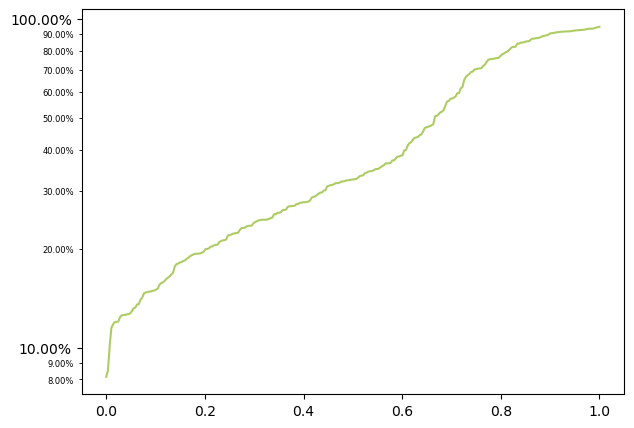

In [167]:
import matplotlib
fig,ax = plt.subplots(figsize = (7,5))

if memory_func == 'first order':
    ax.semilogy(np.linspace(0,1,len(RMSDs_moments)),np.sort(RMSDs_moments),label = 'Moment match.',c = colors[0])
    ax.semilogy(np.linspace(0,1,len(RMSDs_moments)),np.sort(np.minimum(RMSDs_laplace,RMSDs_moments)),label = 'Best fit.',c = colors[2])
ax.semilogy(np.linspace(0,1,len(RMSDs_laplace)),np.sort(RMSDs_laplace),label = 'Laplace dom. fit.',c = colors[1])


ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))
ax.yaxis.set_minor_formatter(matplotlib.ticker.PercentFormatter(decimals = 2,xmax = 1))

ax.tick_params(axis='y', which='major', labelsize=10)
ax.tick_params(axis='y', which='minor', labelsize=6)
for label in axes[0].get_yticklabels():
    label.set_verticalalignment('bottom')

ax.legend(ncols = 2)
ax.set_ylim(0.01,1.0)
ax.set_xlim(0,1)
ax.grid(which='major')
ax.grid(which='minor',linewidth = 0.4)
ax.set_xlabel('Cumulative fraction of fitted breakthrough curves')
ax.set_ylabel('Root-mean-square error', labelpad= 0)

## Global optimization

In [168]:
def RMSE_t_scale(i_btc,t_scale,ts_synth,synth_btc):
    t_peak_synth = ts_synth[np.argmax(synth_btc)]
    btc_interp = np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth,synth_btc)
    a_fac = np.trapezoid(btc_interp*btcs_m_0[i_btc],x = ts_m_0[i_btc])/np.trapezoid(btc_interp**2,x = ts_m_0[i_btc])
    btc_interp_scaled = btc_interp*a_fac
    RMSD = np.sqrt(np.trapezoid((btcs_m_0[i_btc]-btc_interp_scaled)**2,x = ts_m_0[i_btc])/np.trapezoid((btcs_m_0[i_btc])**2,x = ts_m_0[i_btc]))
    return RMSD,btc_interp_scaled,a_fac

In [170]:
global_seed = 43

In [171]:
from scipy.optimize import NonlinearConstraint
p_value = 0.99
def constraint_ellipsoid(mu,Sigma):
    Sigma_inv = np.linalg.inv(Sigma)
    chi2_radius = chi2.ppf(p_value, 3)
        
    def ellipsoid_constraint(x):
        dx = x - mu
        return dx @ Sigma_inv @ dx
    
    constraint = NonlinearConstraint(
        ellipsoid_constraint,
        -np.inf,
        chi2_radius
    )
    return constraint

In [177]:
low_bound = mean_log_params-3*np.sqrt(np.diag(cov_log_params))
up_bound = mean_log_params+3*np.sqrt(np.diag(cov_log_params))
bounds_all = [(low_bound[0],up_bound[0])]+[(np.log(15),np.log(5500))]+[(low_bound[i],up_bound[i]) for i in range(2,4)]
if memory_func == 'power law':
    bounds_all[-1] = (0.0,1.0)

## Synth test

In [179]:
"""
Low-discrepancy (Sobol') sampling, uniform inside a p-confidence ellipsoid
of N(mu, Sigma), with the first coordinate exactly constrained to a
user-given interval [x1_lo, x1_hi].

Derivation
----------
Write Sigma = L L^T (Cholesky, L lower triangular) and let R = sqrt(chi2_p(d))
be the radius of the p-confidence ball in the whitened space. A sample is

    x = mu + L y ,        y uniform on the d-ball of radius R.

Because L is lower triangular, its first row is [L00, 0, ..., 0], so

    x0 = mu0 + L00 * y0                                            (*)

i.e. the first output coordinate depends ONLY on the first pre-rotation
coordinate y0. Two standard facts about uniform distributions on a ball
make this exact and rejection-free:

 1. Marginal of one coordinate of a uniform point on a d-ball of radius R:
        y0 = R t,   (t+1)/2 ~ Beta((d+1)/2, (d+1)/2)   on t in [-1, 1].
    Truncating y0 to an interval is therefore just truncating that Beta
    variable -- done with a single inverse-CDF (one Sobol' dimension).

 2. Conditional on y0, the remaining (y1, ..., y_{d-1}) are uniform on a
    (d-1)-ball of radius Rc = sqrt(R^2 - y0^2) -- sampled the usual way
    (Gaussian-shell direction + radius^(1/(d-1))), also via inverse-CDF,
    so d Sobol' dimensions in total (1 + (d-1) + 1 = d + 1 dimensions
    used overall, same count as the unconstrained problem).

Every generated point satisfies the constraint by construction -- no
points are discarded, so the full low-discrepancy structure of the
Sobol' sequence is preserved (unlike accept/reject filtering).
"""

import numpy as np
from scipy.stats import qmc, chi2, beta
from scipy.special import ndtri


def sobol_uniform_ellipsoid(mu, Sigma, n, p=0.99, x1_bounds=None,
                             scramble=True, seed=None):
    """
    Sobol' low-discrepancy sample of n points, uniform inside the
    p-confidence ellipsoid of N(mu, Sigma), with samples[:, 0] confined
    to x1_bounds = (lo, hi) if given.

    Parameters
    ----------
    mu : (d,) array_like
        Mean vector.
    Sigma : (d, d) array_like
        Covariance matrix (must be positive definite).
    n : int
        Number of samples requested. Internally rounded up to the next
        power of two (best practice for Sobol'), then truncated to n --
        pass n as a power of two yourself if you want to reuse the full
        low-discrepancy set later without truncation.
    p : float, optional
        Confidence level defining the ellipsoid (default 0.99).
    x1_bounds : (lo, hi) tuple, optional
        Hard bounds on the first coordinate of every returned sample.
        If None, unconstrained (equivalent to the pseudo-random version,
        but low-discrepancy).
    scramble : bool, optional
        Use Owen scrambling (recommended; avoids the fixed Sobol' grid
        artifacts and permits randomized-QMC error estimates).
    seed : int or None, optional
        Seed for the scrambling.

    Returns
    -------
    samples : (n, d) ndarray
    """
    mu = np.asarray(mu, dtype=float)
    Sigma = np.asarray(Sigma, dtype=float)
    d = mu.shape[0]

    L = np.linalg.cholesky(Sigma)
    R = np.sqrt(chi2.ppf(p, d))

    # Sobol' sequences are best generated in blocks of size 2**m.
    m_exp = int(np.ceil(np.log2(max(n, 1))))
    n_pow2 = max(1, 2 ** m_exp)

    engine = qmc.Sobol(d=d + 1, scramble=scramble, seed=seed)
    u = engine.random(n_pow2)[:n]  # (n, d+1) in (0, 1)
    eps = 1e-12
    u = np.clip(u, eps, 1 - eps)

    # ---------- 1) first coordinate: exact truncated-Beta inversion ----------
    a = b = 0.5 * (d + 1)  # Beta((d+1)/2, (d+1)/2)

    if x1_bounds is not None:
        lo, hi = x1_bounds
        if L[0, 0] == 0:
            raise ValueError("L[0,0] is zero; cannot constrain x1 this way.")
        t_lo = np.clip((lo - mu[0]) / (L[0, 0] * R), -1.0, 1.0)
        t_hi = np.clip((hi - mu[0]) / (L[0, 0] * R), -1.0, 1.0)
        if t_lo > t_hi:
            t_lo, t_hi = t_hi, t_lo
    else:
        t_lo, t_hi = -1.0, 1.0

    B_lo = beta.cdf(0.5 * (t_lo + 1.0), a, b)
    B_hi = beta.cdf(0.5 * (t_hi + 1.0), a, b)

    Bu = B_lo + u[:, 0] * (B_hi - B_lo)
    Bu = np.clip(Bu, eps, 1 - eps)
    t = 2.0 * beta.ppf(Bu, a, b) - 1.0
    y0 = R * t

    Y = np.zeros((len(u), d))
    Y[:, 0] = y0

    # ---------- 2) remaining d-1 coordinates: uniform on the sub-ball ----------
    if d > 1:
        Rc = np.sqrt(np.maximum(R ** 2 - y0 ** 2, 0.0))

        if d > 2:
            g = ndtri(u[:, 1:d])                      # (n, d-1) quasi-Gaussian
            norms = np.linalg.norm(g, axis=1, keepdims=True)
            norms[norms == 0] = 1.0
            Z = g / norms
        else:  # d == 2 -> 1-d "sphere" is just a sign
            g = ndtri(u[:, 1:2])
            Z = np.sign(g)
            Z[Z == 0] = 1.0

        rad = u[:, d] ** (1.0 / (d - 1))
        Y[:, 1:] = (Rc * rad)[:, None] * Z

    samples = mu + Y @ L.T
    return samples


In [282]:
%%time
np.random.seed(global_seed)
Nt = 150
n_synth = 1000
n_synth_extra = n_synth
if memory_func == 'power law':
    n_synth_extra = 1500
rand_params_synth = np.exp(sobol_uniform_ellipsoid(mean_log_params[1:], cov_log_params[1:][:,1:],
                                                   n_synth_extra,p = p_value,x1_bounds = [np.log(15),np.log(5500)],seed = global_seed))


ts_synth = np.linspace(0,T_,T_*Nt+1)[1:]
if memory_func == 'first order':
    synth_btcs = np.array([forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],theta[1]/theta[2],[theta[2],theta[2]],memory_func,bound_cond)[:,-1] for theta in rand_params_synth])
if memory_func == 'power law':
    synth_btcs = np.array([forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],1.0,[theta[1],np.log(theta[2])],memory_func,bound_cond)[:,-1] for theta in rand_params_synth])
ts_peak_synth = ts_synth[np.argmax(synth_btcs,axis = 1)]
if memory_func == 'power law':
    mask_invalid = (-np.min(synth_btcs,axis = 1)>np.max(synth_btcs,axis = 1)*0.001)|(ts_peak_synth>1.15)
    synth_btcs = synth_btcs[~mask_invalid][:n_synth]
    rand_params_synth = rand_params_synth[~mask_invalid][:n_synth]
    ts_peak_synth = ts_peak_synth[~mask_invalid][:n_synth]

CPU times: total: 1min 27s
Wall time: 1min 27s


In [283]:
%%time
RMSDs_NNI_full = np.zeros(n_btcs)
est_params_NNI_full = np.zeros((n_btcs,5))
btcs_recons_NNI_full = []
for i_btc in range(n_btcs):
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    outs_RMSE_t_scale = [sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,synth_btcs[i])[0], method='bounded', bounds=range_t_scale) for i in range(n_synth)]
    t_scales = [out.x for out in outs_RMSE_t_scale]
    RMSDs = [out.fun for out in outs_RMSE_t_scale]
    btcs_interp_scaled = [RMSE_t_scale(i_btc,t_scales[i],ts_synth,synth_btcs[i])[1] for i in range(n_synth)]
    a_facs_est = np.array([RMSE_t_scale(i_btc,t_scales[i],ts_synth,synth_btcs[i])[2] for i in range(n_synth)])
    RMSDs_NNI_full[i_btc] = np.min(RMSDs)
    NNI_index = np.argmin(RMSDs)
    vs_est = xs_m[i_btc]/(t_scales/ts_peak_synth)
    est_pars = np.concatenate(([a_facs_est[NNI_index],vs_est[NNI_index]],rand_params_synth[NNI_index]))
    est_params_NNI_full[i_btc] = est_pars
    if memory_func == 'first order':
        if ts_m[i_btc][0]>0:
            btcs_recons_NNI_full.append(forward.laplace.ADEMF_1D(ts_m[i_btc],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])
        else:
            btcs_recons_NNI_full.append(np.concatenate(([0],forward.laplace.ADEMF_1D(ts_m[i_btc][1:],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])))
    if memory_func == 'power law':
        if ts_m[i_btc][0]>0:
            btcs_recons_NNI_full.append(forward.laplace.ADEMF_1D(ts_m[i_btc],[xs_m[i_btc]],est_pars[1],est_pars[2],1.0,[est_pars[3],np.log(est_pars[4])],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])
        else:
            btcs_recons_NNI_full.append(np.concatenate(([0],forward.laplace.ADEMF_1D(ts_m[i_btc][1:],[xs_m[i_btc]],est_pars[1],est_pars[2],1.0,[est_pars[3],np.log(est_pars[4])],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])))        
    print(i_btc,np.min(RMSDs))

0 0.07244047520199247
1 0.030842898080092808
2 0.05340100085478515
3 0.049494099162765766
4 0.05660369617280286
5 0.046675125407404476
6 0.031047071569232604
7 0.040463995134978226
8 0.03432624000457577
9 0.056300840279480235
10 0.0265076798866635
11 0.03916016823947719
12 0.04135706525815041
13 0.14025242941965996
14 0.060633790687194
15 0.06739831733565187
16 0.07102382811077974
17 0.15067091837042174
18 0.06758306545289496
19 0.08225973336015921
20 0.046397570022805486
21 0.17907741469452845
22 0.05008941117625392
23 0.04997626541448193
24 0.06498720685644714
25 0.09136669303238881
26 0.050858199197404357
27 0.08745576793895819
28 0.06830866146860372
29 0.08799636403799553
30 0.07018377068663151
31 0.08642261842435797
32 0.17508847858258292
33 0.18360604508755368
34 0.06905605601512464
35 0.11552264097802942
36 0.18855980166530195
37 0.10215321430090622
38 0.053315354186126464
39 0.044366930795309775
40 0.07315712567543553
41 0.24499421516159467
42 0.0550888442481288
43 0.0434514261

### Surrogate model full

In [284]:
%%time
N = 16
if memory_func == 'power law':
    N = 25
btc_mean = np.mean(synth_btcs,axis = 0)
btc_diff = synth_btcs-btc_mean
C = btc_diff.T @ btc_diff / (btc_diff.shape[0] - 1)
eigvals, eigvecs = np.linalg.eigh(C)
idx = np.argsort(eigvals)[::-1]
lambdas = eigvals[idx][:N]
phis = eigvecs[:, idx][:,:N]
Zs = (btc_diff @ eigvecs[:, idx])[:,:N]

CPU times: total: 45.9 s
Wall time: 9.02 s


In [285]:

from scipy.spatial import Delaunay, cKDTree

def linear_ND_interp(tri, tree, x):

    x = np.asarray(x)
    ndim = tri.ndim
    simplex = tri.find_simplex(x)

    if simplex >= 0:
        # Standard barycentric interpolation
        T = tri.transform[simplex, :ndim]
        r = tri.transform[simplex, ndim]

        bary = T @ (x - r)
        weights = np.concatenate([bary, [1 - bary.sum()]])
        vertices = tri.simplices[simplex]

    else:
        # Outside convex hull → nearest vertex
        dist, nearest = tree.query(x)

        vertices = np.zeros(ndim + 1, dtype=int)
        vertices[0] = nearest

        # fill remaining slots with any other indices
        remaining = np.setdiff1d(np.arange(len(tri.points)), [nearest])
        vertices[1:] = remaining[:ndim]

        weights = np.zeros(ndim + 1)
        weights[0] = 1.0
        # vertices, weights = np.zeros(ndim+1).astype(int), np.zeros(ndim+1)+np.nan

    return vertices, weights


def Zs_interpolate(pars,tri,tree,Zs):
    ND_interp_vertices,ND_interp_weights = linear_ND_interp(tri,tree,pars)
    return ND_interp_weights@Zs[ND_interp_vertices],ND_interp_weights@ts_peak_synth[ND_interp_vertices]
    
triangulation = Delaunay(np.log(rand_params_synth))
tree = cKDTree(np.log(rand_params_synth))

#### Surrogate test

In [286]:
def Zs_interpolate(pars,tri,tree,Zs,ts_peak_synth):
    ND_interp_vertices,ND_interp_weights = linear_ND_interp(tri,tree,pars)
    return ND_interp_weights@Zs[ND_interp_vertices],ND_interp_weights@ts_peak_synth[ND_interp_vertices]

In [287]:
%%time
errors_test_LOO = np.zeros(n_synth)
for i in range(n_synth):
    Zs_test_i,t_peak_test_i = Zs_interpolate(np.log(rand_params_synth[i]),Delaunay(np.log(np.delete(rand_params_synth,i,axis = 0))),cKDTree(np.log(np.delete(rand_params_synth,i,axis = 0))),np.delete(Zs,i,axis = 0),np.delete(ts_peak_synth,i))
    btc_synth_test_i = np.interp(ts_synth,ts_synth*t_peak_test_i/ts_peak_synth[i],btc_mean+Zs_test_i@phis.T)
    error_test = utils.errors.RMSD_func(ts_synth,synth_btcs[i],btc_synth_test_i)
    errors_test_LOO[i] = error_test

CPU times: total: 2min 8s
Wall time: 2min 21s


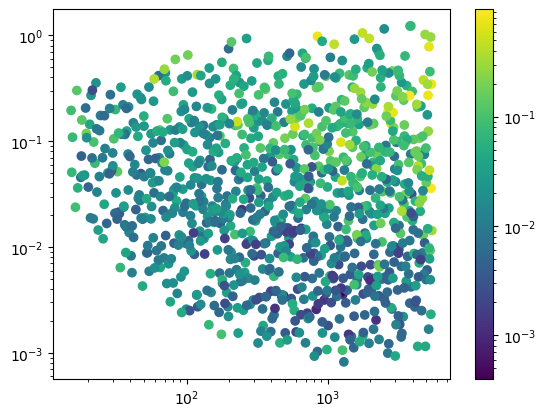

In [288]:
plt.scatter(rand_params_synth[:,0],rand_params_synth[:,1],c=errors_test_LOO,norm = LogNorm())
plt.colorbar()
plt.xscale('log')
plt.yscale('log')

In [289]:
def test_errors_interpolate(pars,tri,tree,errors_test):
    ND_interp_vertices,ND_interp_weights = linear_ND_interp(tri,tree,pars)
    return ND_interp_weights@errors_test[ND_interp_vertices]

#### Surrogate model optimization full

In [290]:
def RMSE_t_scale_Z(i_btc,t_scale,Zs_i,t_peak_synth_interp,btc_mean,phis):
    btc_mean_resampled = np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth_interp,btc_mean)
    phis_resampled = np.array([np.interp(ts_m_0[i_btc],ts_synth*t_scale/t_peak_synth_interp,phi) for phi in phis.T]).T
    btc_interp =  (btc_mean_resampled+Zs_i@(phis_resampled).T)
    a_fac = np.trapezoid(btc_interp*btcs_m_0[i_btc],x = ts_m_0[i_btc])/np.trapezoid(btc_interp**2,x = ts_m_0[i_btc])
    btc_interp_scaled = btc_interp*a_fac
    RMSD = np.sqrt(np.trapezoid((btcs_m_0[i_btc]-btc_interp_scaled)**2,x = ts_m_0[i_btc])/np.trapezoid((btcs_m_0[i_btc])**2,x = ts_m_0[i_btc]))
    return RMSD,btc_interp_scaled

In [291]:
def constraint_ellipsoid_modified(mu,Sigma):
    Sigma_inv = np.linalg.inv(Sigma)
    chi2_radius = chi2.ppf(p_value, 3)
        
    def ellipsoid_constraint(x):
        dx = x[1:] - mu
        return dx @ Sigma_inv @ dx
    
    constraint = NonlinearConstraint(
        ellipsoid_constraint,
        -np.inf,
        chi2_radius
    )
    return constraint

In [292]:
# %%time
from scipy.optimize import differential_evolution
RMSDs_linear_full = np.zeros((n_btcs))
est_params_linear_full = np.zeros((n_btcs,5))
btcs_recons_linear_full = []

for i_btc in range(n_btcs):
    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    
    triangulation = Delaunay(np.log(rand_params_synth))
    tree = cKDTree(np.log(rand_params_synth))
    def loss(par):
        Zs_i,t_peak_synth_interp = Zs_interpolate(par[1:],triangulation,tree,Zs,ts_peak_synth)
        loss_i = RMSE_t_scale_Z(i_btc,par[0],Zs_i,t_peak_synth_interp,btc_mean,phis)[0]**2
        error_est = test_errors_interpolate(par[1:],triangulation,tree,errors_test_LOO)**2
        return loss_i+error_est
    result_DE_linear = differential_evolution(func=loss, bounds=[(range_t_scale[0],range_t_scale[1])]+bounds_all[1:],constraints=(constraint_ellipsoid_modified(mean_log_params[1:],cov_log_params[1:,1:]),),
        strategy='best1bin',popsize=20, recombination=0.7, seed=global_seed)
    est_linear = np.exp(result_DE_linear.x[1:])
    if memory_func == 'first order':
        btc_linear = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,est_linear[0],est_linear[1]/est_linear[2],[est_linear[2],est_linear[2]],memory_func,bound_cond)[:,-1]
    if memory_func == 'power law':
        btc_linear = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,est_linear[0],1.0,[est_linear[1],np.log(est_linear[2])],memory_func,bound_cond)[:,-1]
    t_scale_linear = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_linear)[0], method='bounded', bounds=range_t_scale).x
    RMSD,btc_interp_scaled,a_fac = RMSE_t_scale(i_btc,t_scale_linear,ts_synth,btc_linear)
    v_est = xs_m[i_btc]/(t_scale_linear/ts_synth[np.argmax(btc_linear)])
    est_pars = [a_fac,v_est,*est_linear]
    est_params_linear_full[i_btc] = est_pars
    RMSDs_linear_full[i_btc] = min(RMSDs_NNI_full[i_btc],RMSD)
    if memory_func == 'first order':
        if ts_m[i_btc][0]>0:
            btcs_recons_linear_full.append(forward.laplace.ADEMF_1D(ts_m_0[i_btc],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])
        else: 
            btcs_recons_linear_full.append(np.concatenate(([0],forward.laplace.ADEMF_1D(ts_m_0[i_btc][1:],[xs_m[i_btc]],est_pars[1],est_pars[2],est_pars[3]/est_pars[4],[est_pars[4],est_pars[4]],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])))
    if memory_func == 'power law':
        if ts_m[i_btc][0]>0:
            btcs_recons_linear_full.append(forward.laplace.ADEMF_1D(ts_m_0[i_btc],[xs_m[i_btc]],est_pars[1],est_pars[2],1.0,[est_pars[3],np.log(est_pars[4])],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])
        else: 
            btcs_recons_linear_full.append(np.concatenate(([0],forward.laplace.ADEMF_1D(ts_m_0[i_btc][1:],[xs_m[i_btc]],est_pars[1],est_pars[2],1.0,[est_pars[3],np.log(est_pars[4])],memory_func,bound_cond)[:,-1]*est_pars[0]/est_pars[1]*xs_m[i_btc])))
    print(i_btc,RMSDs_NNI_full[i_btc],RMSD,np.sqrt(result_DE_linear.fun))

0 0.07244047520199247 0.0760099814680807 0.07562492388351352
1 0.030842898080092808 0.07485004512780308 0.07479610465230543
2 0.05340100085478515 0.05312633216923913 0.0585025408729101
3 0.049494099162765766 0.043656803796419785 0.049911790517899686
4 0.05660369617280286 0.048168848933668476 0.05184211818837075
5 0.046675125407404476 0.05577986123028781 0.057266966547154415
6 0.031047071569232604 0.06699496345662592 0.037092613039278036
7 0.040463995134978226 0.06658210995791515 0.0566044183935745
8 0.03432624000457577 0.06402804210256488 0.053103652511404524
9 0.056300840279480235 0.07261208012599324 0.06573226456408648
10 0.0265076798866635 0.08959873981279713 0.06074362778676148
11 0.03916016823947719 0.0761566344070339 0.07603050998057964
12 0.04135706525815041 0.07950805115681414 0.055657003575755766
13 0.14025242941965996 0.23333719584200976 0.12448384522767766
14 0.060633790687194 0.07081278027808223 0.07118660931439429
15 0.06739831733565187 0.08206319399818478 0.07985375867488

In [293]:
%%time
n_evals=100
est_params_local = np.zeros((n_btcs,3))
nfev_local = np.zeros(n_btcs)
histories_local = np.zeros((n_btcs,n_evals))
histories_params_local = np.zeros((n_btcs,n_evals,4))
for i_btc in range(n_btcs):
    print(i_btc)
    history = []
    history_params = []

    range_t_scale_rel_val = 0.8
    index_max_first,index_max_last = np.where(btcs_m_0[i_btc]>range_t_scale_rel_val*np.max(btcs_m_0[i_btc]))[0][[0,-1]]
    def interp_rel_val(index):
        return (ts_m_0[i_btc][index-1]
                +(ts_m_0[i_btc][index]-ts_m_0[i_btc][index-1])
                /(btcs_m_0[i_btc][index]/np.max(btcs_m_0[i_btc])-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc]))
                *(range_t_scale_rel_val-btcs_m_0[i_btc][index-1]/np.max(btcs_m_0[i_btc])))
    range_t_scale = [interp_rel_val(index_max_first),interp_rel_val(index_max_last+1)]
    
    def loss(phi):
        theta = np.exp(phi)
        if memory_func == 'first order':
            btc_synth = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],theta[1]/theta[2],[theta[2],theta[2]],memory_func,bound_cond)[:,-1]
        if memory_func == 'power law':
            btc_synth = forward.laplace.ADEMF_1D(ts_synth,[1.0],1.0,theta[0],1.0,[theta[1],np.log(theta[2])],memory_func,bound_cond)[:,-1]
        output = sp.optimize.minimize_scalar(lambda x: RMSE_t_scale(i_btc,x,ts_synth,btc_synth)[0], method='bounded', bounds=range_t_scale)
        v = xs_m[i_btc]/(output.x/ts_synth[np.argmax(btc_synth)])
        loss = output.fun
        history.append(loss)
        history_params.append([v,*theta])
        return loss
    
    bounds = [(np.log(15),np.log(5500))]+[(mean_log_params[i+1]-cov_log_params[i+1,i+1],
               mean_log_params[i+1]+cov_log_params[i+1,i+1]) for i in range(1,3)]
    x0 = np.log(est_params_linear_full[i_btc][2:])
    local_result = sp.optimize.minimize(loss,x0 = x0 ,method="Nelder-Mead",options={'maxfev': n_evals},bounds = bounds)

    histories_local[i_btc][:min(len(history),n_evals)] = history[:min(len(history),n_evals)]
    histories_params_local[i_btc][:min(len(history),n_evals)] = history_params[:min(len(history),n_evals)]
    est_params_local[i_btc] = np.exp(local_result.x)
    print(local_result.success,np.min(history))

0


<timed exec>:36: OptimizeWarning: Initial guess is not within the specified bounds


True 0.07300760197872944
1
False 0.025741343463642378
2
True 0.05464892973343969
3
True 0.0485033887330656
4
True 0.04011976149276246
5
True 0.04722543772009117
6
False 0.036097294061868006
7
False 0.04296242924817284
8
True 0.03720161454820977
9
True 0.053501664178284905
10
False 0.02308120051742075
11
True 0.03827846068438228
12
True 0.03220838526108569
13
False 0.13410612755959406
14
False 0.05967117749424115
15
False 0.07046556017073985
16
False 0.06997143097985253
17
False 0.22529330580525414
18
False 0.06195818838787502
19
False 0.07770577304972275
20
True 0.052958974584642056
21
False 0.15843020037355926
22
False 0.05427199738681966
23
False 0.04745772057550487
24
False 0.060885231866530304
25
True 0.09114471246122521
26
False 0.05273521550988284
27
False 0.08666640625296744
28
True 0.07358030539477037
29
True 0.08686867478657222
30
False 0.07965969459525657
31
False 0.08751276076006943
32
True 0.1712821527869721
33
True 0.1838065733495812
34
False 0.05844212740233882
35
False 0

0.4373601903808255 0.324774992873133
0.2833055357153556 0.19023370612677187
0.07386022916276187 0.06671789753566613
0.07257623451236989 0.06517149472809285


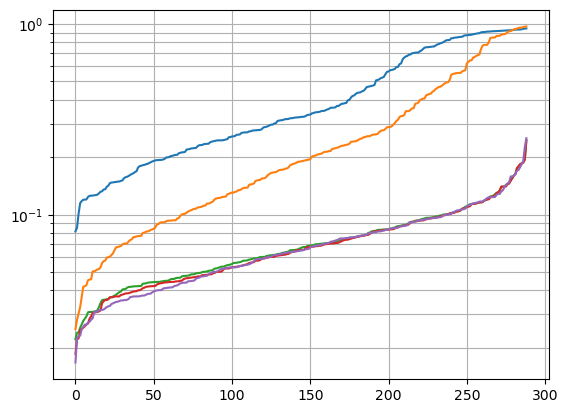

In [294]:
plt.semilogy(np.sort(RMSDs_laplace))
plt.semilogy(np.sort(RMSDs_moments))
plt.semilogy(np.sort(RMSDs_NNI_full))
plt.semilogy(np.sort(RMSDs_linear_full))
plt.semilogy(np.sort([np.min(hist[hist>0]) for hist in histories_local]))
print(np.mean(RMSDs_laplace),np.median(RMSDs_laplace))
print(np.mean(RMSDs_moments),np.median(RMSDs_moments))
print(np.mean(RMSDs_NNI_full),np.median(RMSDs_NNI_full))
print(np.mean(RMSDs_linear_full),np.median(RMSDs_linear_full))
plt.grid(which = 'both')

In [295]:
best_params = np.array([hist_pars[np.argmin(hist[hist>0])] for hist,hist_pars in zip(histories_local,histories_params_local)])

In [296]:
if memory_func == 'power law':
    best_params[:,-1] = np.log(best_params[:,-1])

In [297]:
np.save('best_est_params_'+memory_func+'_'+bound_cond+'.npy', np.concatenate((np.array(names_list)[:,None],best_params),axis = 1))

# Schematic plots

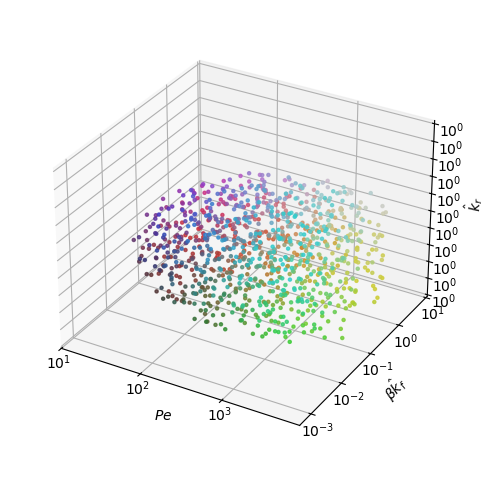

In [246]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.ticker as mticker

# Normalize log values to [0, 1] for RGB mapping
def normalize(a):
    return np.clip((a - a.min()) / (a.max() - a.min()),0.2,0.8)

# Normalize using ±2σ from the mean
def normalize_2sigma(a):
    mu = np.mean(a)
    sigma = np.std(a)
    z = (a - (mu - 2*sigma)) / (4 * sigma)
    z_clipped = np.clip(z, 0.2, 0.8)
    return  z_clipped # Range maps to [0,1]

r = normalize_2sigma(np.log(rand_params_synth[:,1]))
g = normalize(np.log(rand_params_synth[:,0]))
b = normalize_2sigma(np.log(rand_params_synth[:,2]))
colors = np.stack([r, g, b], axis=1)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
def log_tick_formatter(val, pos=None):
    return f"$10^{{{int(val)}}}$"
scatter = ax.scatter(np.log10(rand_params_synth[:,0]), np.log10(rand_params_synth[:,1]), np.log10(rand_params_synth[:,2]), c=colors, alpha = 0.8, s = 5)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(log_tick_formatter))
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(log_tick_formatter))
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.zaxis.set_major_formatter(mticker.FuncFormatter(log_tick_formatter))
ax.zaxis.set_major_locator(mticker.MaxNLocator(integer=True))

ax.tick_params(axis='x', pad=-5)
ax.tick_params(axis='y', pad=-3)
ax.tick_params(axis='z', pad=0)

ax.set_xlabel(r'$Pe$', labelpad=-4)
ax.set_ylabel(r'$\beta \hat{k}_f$', labelpad=0)
ax.set_zlabel(r'$\hat{k}_r$', labelpad=0)
ax.set_box_aspect(aspect=None, zoom=0.92)

plt.show()

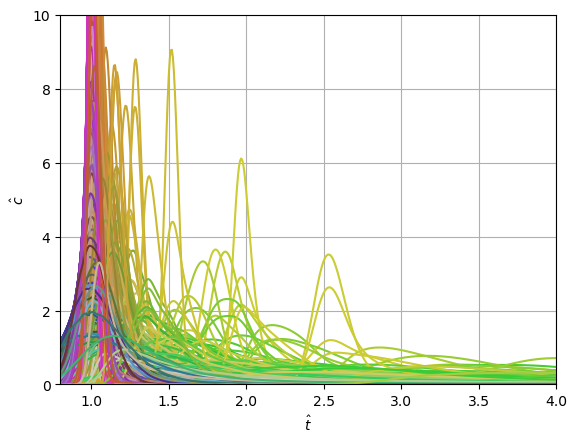

In [264]:
fig = plt.figure()
ax = fig.add_subplot(111)
for i in range(0,1000):
    ax.plot(ts_synth,btc_mean+phis@Zs[i],c=colors[i], alpha = 1.0)
ax.set_xlim(0.8,4.0)
ax.set_ylim(0,10)
ax.set_xlabel(r'$\hat{t}$')
ax.set_ylabel(r'$\hat{c}$')
ax.grid()

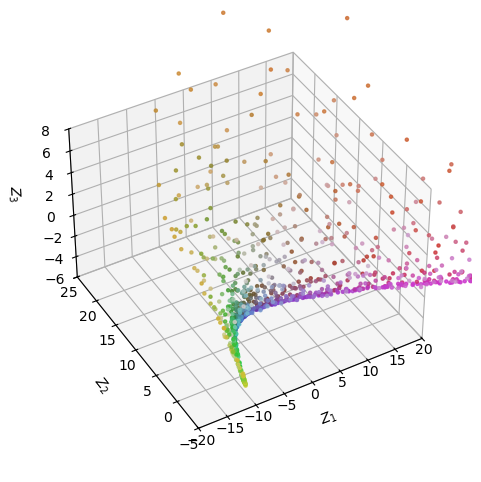

In [248]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.ticker as mticker

# Normalize log values to [0, 1] for RGB mapping
def normalize(a):
    return np.clip((a - a.min()) / (a.max() - a.min()),0.2,0.8)

# Normalize using ±2σ from the mean
def normalize_2sigma(a):
    mu = np.mean(a)
    sigma = np.std(a)
    z = (a - (mu - 2*sigma)) / (4 * sigma)
    z_clipped = np.clip(z, 0.2, 0.8)
    return  z_clipped # Range maps to [0,1]

r = normalize(np.log(rand_params_synth[:,0]))
g = normalize_2sigma(np.log(rand_params_synth[:,1]))
b = normalize_2sigma(np.log(rand_params_synth[:,2]))
colors = np.stack([r, g, b], axis=1)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
def log_tick_formatter(val, pos=None):
    return f"$10^{{{int(val)}}}$"
scatter = ax.scatter(Zs[:,0], Zs[:,1], Zs[:,2], c=colors[:], alpha = 0.8, s = 5)
ax.set_xlim(-20,20)
ax.set_ylim(-5,25)
ax.set_zlim(-6,8)
# ax.plot(Zs_btc_0[:,0],Zs_btc_0[:,1], c = 'k')

ax.tick_params(axis='x', pad=-5)
ax.tick_params(axis='y', pad=-1)
# ax.tick_params(axis='z', pad=-0.7)

ax.set_xlabel(r'$Z_1$', labelpad=0)
ax.set_ylabel(r'$Z_2$', labelpad=6)
ax.set_zlabel(r'$Z_3$', labelpad=9)
ax.set_box_aspect(aspect=None, zoom=0.87)
ax.view_init(40,-120,0)
plt.show()